# Weights matrix for Moran's I

In [1]:
import geopandas as gpd
import libpysal

from desakota.paths import DataLayout

layout = DataLayout.from_env().ensure()
communes = gpd.read_file(layout.processed / 'communes_ql18_corridor.gpkg')  # EPSG:32648, from 01


def build_queen_weights(units: gpd.GeoDataFrame) -> libpysal.weights.W:
    """Queen contiguity (shared edge or vertex), row-standardised.

    A unit with no contiguous neighbour (Tuần Châu: an island tied to Hạ Long by a
    causeway) would get a zero row, i.e. a spatial lag of 0, which drags Moran's I
    toward a spurious low-high pairing. It is attached to its single nearest
    neighbour instead (KNN-1 on centroids), the usual libpysal remedy.
    """
    w_queen = libpysal.weights.Queen.from_dataframe(units, use_index=True)
    if w_queen.islands:
        w_knn1 = libpysal.weights.KNN.from_dataframe(units, k=1, use_index=True)
        w_queen = libpysal.weights.attach_islands(w_queen, w_knn1)
    w_queen.transform = 'r'
    return w_queen


w_queen = build_queen_weights(communes)
w_queen.n, w_queen.islands, w_queen.n_components

/mnt/c/Users/ADMIN/Desktop/projects/ai_tools/ntl_analysis/.venv/lib/python3.14/site-packages/libpysal/weights/contiguity.py:354: UserWarning: The weights matrix is not fully connected: 
 There are 2 disconnected components.
 There is 1 island with id: 117.
  W.__init__(self, neighbors, ids=ids, **kw)
/mnt/c/Users/ADMIN/Desktop/projects/ai_tools/ntl_analysis/.venv/lib/python3.14/site-packages/libpysal/weights/distance.py:164: UserWarning: The weights matrix is not fully connected: 
 There are 35 disconnected components.
  W.__init__(self, neighbors, id_order=ids, **kwargs)


(171, [], 1)

/mnt/c/Users/ADMIN/Desktop/projects/ai_tools/ntl_analysis/.venv/lib/python3.14/site-packages/spreg/diagnostics.py:620: ComplexWarning: Casting complex values to real discards the imaginary part
  ci_result = sqrt(max_eigval / min_eigval)


(<Figure size 700x700 with 1 Axes>,
 <Axes: title={'center': 'Moran Scatterplot (0.57)'}, xlabel='Attribute', ylabel='Spatial Lag'>)

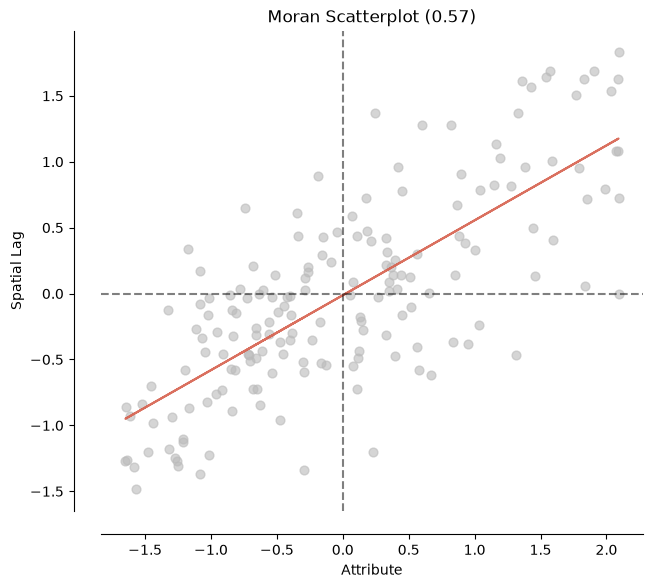

In [2]:
import esda
from splot.esda import lisa_cluster, moran_scatterplot

moran_built_frac = esda.moran.Moran(communes['built_frac'], w_queen)

# moran_built_frac.I
# moran_built_frac.p_sim

moran_scatterplot(moran_built_frac)

# Local Moran's I (LISA)

(<Figure size 640x480 with 1 Axes>, <Axes: >)

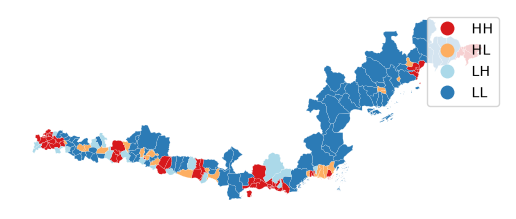

In [3]:
lisa_built_frac = esda.moran.Moran_Local(communes['built_frac'], w_queen)

lisa_cluster(lisa_built_frac, communes, p=0.5)